In [1]:
from utils.conversions import proximity_graph_creator, graph_creator
from utils.embed import embed_graph
from rdkit.Chem import Draw
from rdkit import Chem
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import networkx as nx

In [2]:
creator = proximity_graph_creator(distance=2.25)

In [3]:
data = pd.read_csv("data/data.csv").loc[:99, ["SMILES"]]
data

/tmp/ipykernel_21505/1047973088.py:1: DtypeWarning: Columns (8: available amount 3 (mg)) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("data/data.csv").loc[:99, ["SMILES"]]


,SMILES
0,C1(Br)C=CC(C=O)=CC=1Br
1,N(=O)(=O)C1C=C(Br)C=CC=1C=O
2,N1C2C=CC=CC=2CCC(Br)C1=O
3,N1C2C=CC(=CC=2C(CCO)=C1)Br
4,COC1=C(OC)C=C(CC#N)C(Br)=C1
...,...
95,C12CNCCC1=CC=C(Cl)C=2
96,BrC1C=C(S(C)(=O)=O)C=CN=1
97,FC1=CC=C(C(=C1)N)NC(C1=CC=C(C=C1)CNC(/C=C/C1C=...
98,O=C(C1C(C)=C(N(=O)=O)C(F)=CC=1)O


In [8]:
data["embeddings"] = [ embed_graph(creator.createFromSmiles(smiles), normalize=True) for smiles in data["SMILES"] ]
data

Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total elapsed time: 0.0000 sec
Total el

,SMILES,embeddings,similarity
0,C1(Br)C=CC(C=O)=CC=1Br,"[0.13990841029157966, 0.21599289765287644, 0.1...",1.000000
1,N(=O)(=O)C1C=C(Br)C=CC=1C=O,"[0.14784732829182418, 0.20620153076888664, 0.1...",0.855398
2,N1C2C=CC=CC=2CCC(Br)C1=O,"[0.06084972974585469, 0.1766479781954416, 0.15...",0.769481
3,N1C2C=CC(=CC=2C(CCO)=C1)Br,"[0.04028185068661955, 0.20093219202338466, 0.1...",0.653223
4,COC1=C(OC)C=C(CC#N)C(Br)=C1,"[0.02487838748970572, 0.1004042963246561, 0.10...",0.467851
...,...,...,...
95,C12CNCCC1=CC=C(Cl)C=2,"[0.0722917635530928, 0.182089013147936, 0.1498...",0.782766
96,BrC1C=C(S(C)(=O)=O)C=CN=1,"[0.09563612378153581, 0.20598266960057404, 0.0...",0.702403
97,FC1=CC=C(C(=C1)N)NC(C1=CC=C(C=C1)CNC(/C=C/C1C=...,"[0.09920823708219881, 0.20692038409232724, 0.1...",0.863574
98,O=C(C1C(C)=C(N(=O)=O)C(F)=CC=1)O,"[0.06765644777789306, 0.12027101909367678, 0.1...",0.558295


In [9]:
data["similarity"] = np.dot( np.stack(data["embeddings"].to_numpy()), np.asarray(data.loc[0, "embeddings"]) )
sorted_df = data.sort_values("similarity", ascending=False)
sorted_df[sorted_df["similarity"] > 0.85]

,SMILES,embeddings,similarity
0,C1(Br)C=CC(C=O)=CC=1Br,"[0.13990841029157966, 0.21599289765287644, 0.1...",1.000000
55,N#CC1C=CC(C(Cl)Cl)=CC=1,"[0.1239319458347083, 0.198486136646168, 0.1677...",0.896335
23,C1=C(O)C=CN=C1Br,"[0.04238059280292953, 0.20793216764764755, 0.1...",0.894530
71,NC1C(F)=CC=C(C#C)C=1,"[0.11945149886134086, 0.1768036206649582, 0.15...",0.881827
1,N(=O)(=O)C1C=C(Br)C=CC=1C=O,"[0.14784732829182418, 0.20620153076888664, 0.1...",0.880648
75,N#CC1C=NC=C(F)C=1,"[0.0511441033797189, 0.17617125290371893, 0.14...",0.866800
26,N1C=C(C=CC=1O)I,"[0.10632782101554707, 0.20985663987016567, 0.1...",0.856175


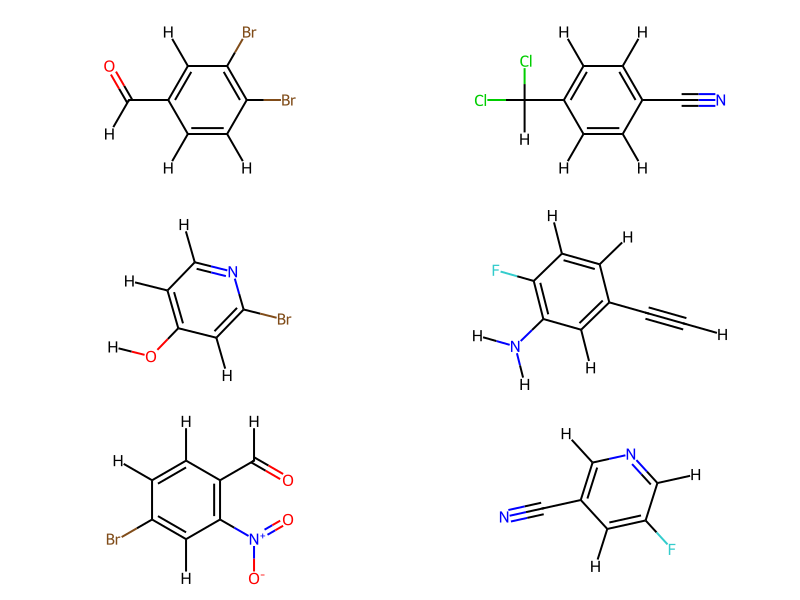

In [10]:
mols = [Chem.AddHs(Chem.MolFromSmiles(smiles)) for smiles in sorted_df.iloc[:6, 0]]
Draw.MolsToGridImage(mols, molsPerRow=2, subImgSize=(400, 200))